In [1]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for EDA story extraction framework loaded successfully.")

Global libraries for EDA story extraction framework loaded successfully.


### 1. Formulating Hypotheses from Visualizations

Conversion rate by device:
 device
Desktop    0.15
Mobile     0.05
Name: conversion, dtype: float64


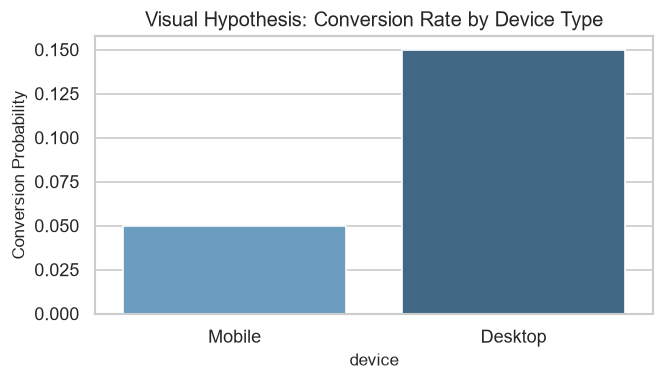

In [8]:
np.random.seed(42)
df_hyp = pd.DataFrame({
    'device': ['Mobile'] * 100 + ['Desktop'] * 100,
    'conversion': np.concatenate([np.random.binomial(1,0.05,100), np.random.binomial(1,0.12,100)])
})
# print(df_hyp.tail())
# print(df_hyp.head())
conversion_rate_by_device = df_hyp.groupby('device')['conversion'].mean()
print("Conversion rate by device:\n", conversion_rate_by_device)

# visualization
plt.figure(figsize=(6,3))
sns.barplot(x='device', y='conversion', hue='device', data=df_hyp, palette='Blues_d', legend=False, errorbar=None)
plt.title('Visual Hypothesis: Conversion Rate by Device Type')
plt.ylabel('Conversion Probability')
plt.show()

In [12]:
from scipy import stats
np.random.seed(42)

# Control Group (Standard Practice): Average strike rate around 125
control_group = np.random.normal(loc=125.0, scale=8.0, size=25)
# print("Controlling group Strike Rates: ", control_group)

# Treatment Group (Power-Hitting Camp): Average strike rate around 135
camp_group = np.random.normal(loc=135.0, scale=8.0, size=25)
print("Treatment Group Strike Rates:\n", camp_group)


# Formulating Hypotheses 
# Null Hypothesis (H0): The average strike rate of the control group is equal to the average strike rate of the Power Hitting Camp group.
# Alternative Hypothesis (H1): The average strike rate of the Power Hitting Camp group is higher than that of the control group.

# run independent one-sided t-test (testing if the Power Hitting Camp group has a higher average strike rate than the control group)
# t-test : means comparison between two independent groups : one-sided test to check if the mean of the first group is greater than the mean of the second group
t_statistics, p_value = stats.ttest_ind(camp_group, control_group, alternative='greater')

print(f"Average Strike Rate - Control Group: {np.mean(control_group):.2f}")
print(f"Average Strike Rate - Power Hitting Camp Group: {np.mean(camp_group):.2f}")
print("_" * 60)
print(f"T-Statistics: {t_statistics:.2f}")
print(f"P-Value: {p_value:.4f}")
print("_" * 60)
if p_value < 0.05:
    print("Result: Reject the null hypothesis. The Power Hitting Camp group has a significantly higher average strike rate.")
else:
    print("Result: Fail to reject the null hypothesis. There is no significant difference in average strike rates.")

Treatment Group Strike Rates:
 [135.88738072 125.79205138 138.00558415 130.19489048 132.66645
 130.1863471  149.81822548 134.8920222  126.53831257 141.5803593
 125.2332508  136.67090876 119.32263901 124.37451161 136.57488989
 140.90773264 136.37094625 134.07481374 132.59117044 123.17182408
 129.24124633 131.31488983 143.45697781 137.74894632 120.89567876]
Average Strike Rate - Control Group: 123.69
Average Strike Rate - Power Hitting Camp Group: 132.70
____________________________________________________________
T-Statistics: 4.23
P-Value: 0.0001
____________________________________________________________
Result: Reject the null hypothesis. The Power Hitting Camp group has a significantly higher average strike rate.


### 2. Segment-Based Deep Dives (Slicing and Dicing)


region      North  South
tier                    
Enterprise   0.01   0.02
Free         0.25   0.28
Pro          0.05   0.04


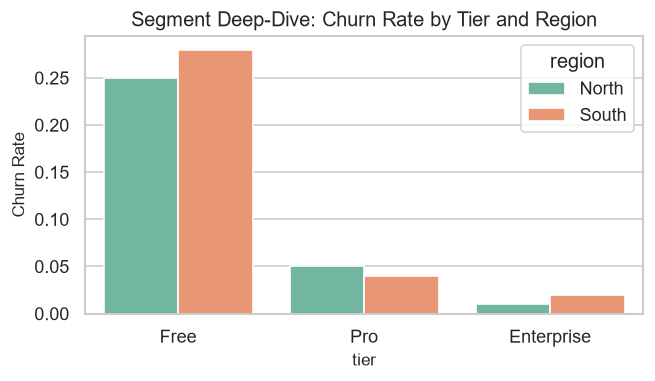

In [14]:
df_seg = pd.DataFrame({
    'tier': ['Free', 'Free', 'Pro', 'Pro', 'Enterprise', 'Enterprise'],
    'region': ['North', 'South', 'North', 'South', 'North', 'South'],
    'churn_rate': [0.25, 0.28, 0.05, 0.04, 0.01, 0.02]
})

print(df_seg.pivot(index='tier', columns='region', values='churn_rate'))

# visualization
plt.figure(figsize=(6, 3))
sns.barplot(x='tier', y='churn_rate', hue='region', data=df_seg, palette='Set2', errorbar=None)
plt.title('Segment Deep-Dive: Churn Rate by Tier and Region')
plt.ylabel('Churn Rate')
plt.show()

### 3. Identifying Confounders and Simpson’s Paradox in EDA

In [21]:
data = [
    # Batter A: Great overall, but plays mostly on brutal turning tracks (90 out of 100 innings)
    {'Batter': 'Batter A', 'Pitch': 'Flat', 'Innings': 10, 'Runs': 550},
    {'Batter': 'Batter A', 'Pitch': 'Turning', 'Innings': 90, 'Runs': 3150},
    
    # Batter B: Weaker on both pitches, but plays almost entirely on easy flat tracks (90 out of 100 innings)
    {'Batter': 'Batter B', 'Pitch': 'Flat', 'Innings': 90, 'Runs': 4500},
    {'Batter': 'Batter B', 'Pitch': 'Turning', 'Innings': 10, 'Runs': 300},
]
df = pd.DataFrame(data)
# print(df)
df["Average"]= df["Runs"] / df["Innings"]
print(df)
print("_" * 60)
print(" Break down by pitch type")
print(df[['Batter', 'Pitch','Innings' ,'Average']])
print("_" * 60)
print(df.pivot(index='Batter', columns='Pitch', values='Average'))  
print("_" * 60)
overall = df.groupby('Batter').agg({'Innings': 'sum', 'Runs': 'sum'}).reset_index()
print(overall)
print("_" * 60)
overall['Overall_Average'] = overall['Runs'] / overall['Innings']
print(overall[["Batter", "Innings", "Overall_Average"]])
print("_" * 60)

     Batter    Pitch  Innings  Runs  Average
0  Batter A     Flat       10   550     55.0
1  Batter A  Turning       90  3150     35.0
2  Batter B     Flat       90  4500     50.0
3  Batter B  Turning       10   300     30.0
____________________________________________________________
 Break down by pitch type
     Batter    Pitch  Innings  Average
0  Batter A     Flat       10     55.0
1  Batter A  Turning       90     35.0
2  Batter B     Flat       90     50.0
3  Batter B  Turning       10     30.0
____________________________________________________________
Pitch     Flat  Turning
Batter                 
Batter A  55.0     35.0
Batter B  50.0     30.0
____________________________________________________________
     Batter  Innings  Runs
0  Batter A      100  3700
1  Batter B      100  4800
____________________________________________________________
     Batter  Innings  Overall_Average
0  Batter A      100             37.0
1  Batter B      100             48.0
___________________

          X         Y    Group
0  1.000000  8.099343  Group A
1  1.081633  7.890714  Group A
2  1.163265  7.966272  Group A


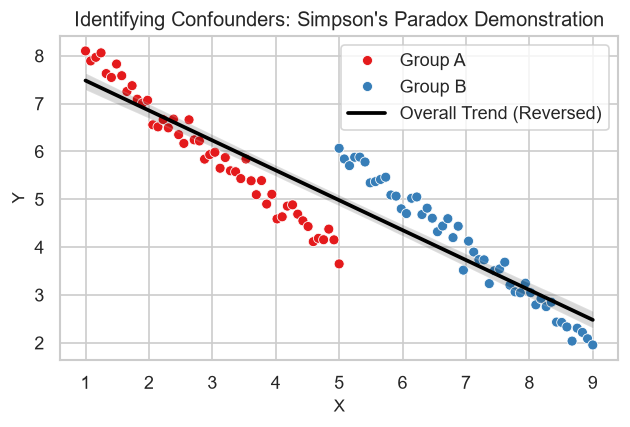

In [22]:
np.random.seed(42)
n = 100
x_simpson = np.concatenate([np.linspace(1, 5, 50), np.linspace(5, 9, 50)])
y_simpson = np.concatenate([np.linspace(8, 4, 50), np.linspace(6, 2, 50)]) + np.random.normal(0, 0.2, 100)
group = ['Group A']*50 + ['Group B']*50
df_simpson = pd.DataFrame({'X': x_simpson, 'Y': y_simpson, 'Group': group})
print(df_simpson.head(3))

# Visualization
plt.figure(figsize=(6, 3.5))
sns.scatterplot(x='X', y='Y', hue='Group', data=df_simpson, palette='Set1')
sns.regplot(x='X', y='Y', data=df_simpson, scatter=False, color='black', label='Overall Trend (Reversed)')
plt.title("Identifying Confounders: Simpson's Paradox Demonstration")
plt.legend()
plt.show()